# Doprinos 7 — Streaming simulacija: 5 snimaka × 3 koraka × 4 režima

Glavni eksperiment nad snimcima 36–40, koraci **2, 5 i 10 sekundi**, režimi A/B/C/D. Algoritam i parametri su zadržani iz prethodno proverenog pilota; ne podešavaju se na test referencama. Rezultati se čuvaju pod prefiksom `07_FINAL_` odvojeno od pilota. Ovo je **simulacija segmentne obrade**, ne pravi streaming API. Prikazano vreme do rezultata je procena zasnovana na trajanju snimka i merenom CPU vremenu.


In [1]:
from pathlib import Path
import math, re, time, unicodedata, wave
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import resample_poly
from faster_whisper import WhisperModel
from jiwer import wer, process_words
from IPython.display import display

print('Biblioteke učitane.')

Biblioteke učitane.


In [2]:
# ============================================================
# PUTANJE
# ============================================================

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

AUDIO_DIR = PROJECT_ROOT / "audio" / "40Sentences00-08Notebooks"
REZULTATI_DIR = PROJECT_ROOT / "rezultati" / "07_streaming_chunking_real_time"

REZULTATI_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("AUDIO_DIR:", AUDIO_DIR)
print("REZULTATI_DIR:", REZULTATI_DIR)


PROJECT_ROOT: D:\0000000000MasterRad\aleksandar_jovanović_Faster-Whisper&CTranslate2_2026\Projekat2ASR
AUDIO_DIR: D:\0000000000MasterRad\aleksandar_jovanović_Faster-Whisper&CTranslate2_2026\Projekat2ASR\audio\40Sentences00-08Notebooks
REZULTATI_DIR: D:\0000000000MasterRad\aleksandar_jovanović_Faster-Whisper&CTranslate2_2026\Projekat2ASR\rezultati\07_streaming_chunking_real_time


In [3]:
REFERENCE = {36: 'Savremeni sistemi za automatsko prepoznavanje govora imaju veliki broj praktičnih primena. Mogu se koristiti za automatsko pravljenje transkripata sastanaka, generisanje titlova, glasovne asistente, pretragu multimedijalnog sadržaja i poboljšanje pristupačnosti digitalnih sistema. Ipak, kvalitet njihovog rada zavisi od velikog broja faktora. Govornici imaju različite glasove, akcente i brzine govora, dok snimci mogu nastati korišćenjem različitih mikrofona i u različitim prostorijama. Dodatni problem predstavlja pozadinski šum. Sistem koji veoma dobro radi u tihoj prostoriji ne mora da postigne isti rezultat na ulici ili u automobilu. Zbog toga evaluacija sistema ne bi trebalo da bude zasnovana na samo jednom zvučnom zapisu. Potrebno je koristiti više govornika, različite dužine snimaka i različite uslove. Pored tačnosti transkripcije, važno je analizirati vreme izvršavanja, potrošnju memorije i sposobnost sistema da obrađuje zvuk dovoljno brzo za praktičnu primenu.', 37: 'Kada govorimo o performansama modela za prepoznavanje govora, postoje dve različite stvari koje želimo da postignemo. Prva je što tačniji transkript, a druga što efikasnije izvršavanje. Veći model može bolje da prepozna komplikovane rečenice ili govor u težim uslovima, ali istovremeno može zahtevati mnogo više memorije i vremena. Manji model može biti nešto manje precizan, ali dovoljno brz da se koristi na običnom laptopu. Kvantizacija predstavlja još jedan način optimizacije jer omogućava korišćenje numeričkog formata manje preciznosti. Time se može smanjiti količina potrebne memorije i ubrzati obrada. Međutim, svaka optimizacija mora da bude eksperimentalno proverena. Nije dovoljno pokazati da je jedna konfiguracija brža. Potrebno je proveriti i da li je njena tačnost ostala prihvatljiva. Upravo zato se koriste metrike kao što su Word Error Rate, latencija i Real-Time Factor, koje omogućavaju da različite konfiguracije modela budu upoređene na objektivan način.', 38: 'Prošle nedelje imao sam prilično ispunjen dan. Ujutru sam ustao ranije jer sam morao da završim nekoliko obaveza pre odlaska u grad. Posle doručka proverio sam poruke, pripremio stvari koje su mi bile potrebne i krenuo automobilom. Na putu je bilo više saobraćaja nego što sam očekivao, pa mi je trebalo skoro pola sata da stignem do centra. Prvo sam otišao do prodavnice, zatim do banke, a nakon toga sam se našao sa prijateljem kojeg nisam video nekoliko meseci. Razgovarali smo o poslu, putovanjima i planovima za narednu godinu. Posle ručka vreme se iznenada promenilo i počela je jaka kiša. Sačekali smo nekoliko minuta da se vreme malo smiri, a onda smo krenuli kući. Kada sam se vratio, nastavio sam da radim na računaru. Uveče sam završio preostale obaveze i odlučio da ostatak dana provedem odmarajući se.', 39: 'Sistem koji obrađuje govor u realnom vremenu mora da rešava nešto drugačiji problem od sistema koji dobije kompletan audio zapis. Kod klasične transkripcije model može da dobije čitav snimak i zatim ga obradi. Kod realnog vremena zvuk neprestano pristiže, pa ga je potrebno podeliti na manje delove. Ako koristimo veoma kratke segmente, sistem može brzo da prikaže rezultat, ali model ima manje konteksta za pravilno prepoznavanje rečenice. Sa druge strane, ako koristimo duge segmente, model dobija više konteksta, ali korisnik mora duže da čeka na rezultat. Zbog toga izbor veličine segmenta predstavlja kompromis između latencije i kvaliteta transkripcije. Na primer, mogu se uporediti segmenti od dve, pet i deset sekundi. Za svaku konfiguraciju moguće je izmeriti vreme obrade, faktor realnog vremena i tačnost konačnog transkripta. Takav eksperiment omogućava da se utvrdi koja konfiguracija predstavlja najbolji kompromis za praktičan sistem.', 40: 'Cilj eksperimentalne analize sistema za automatsko prepoznavanje govora jeste da se utvrdi kako različiti faktori utiču na njegov rad. Možemo menjati veličinu modela, nivo pozadinskog šuma, jezik govornika, parametre dekodiranja, način kvantizacije ili korišćenje algoritma za detekciju govora. Svaki eksperiment treba organizovati tako da možemo jasno da utvrdimo posledice određene promene. Rezultati se zatim mogu posmatrati kroz više metrika. Word Error Rate pokazuje koliko se prepoznati tekst razlikuje od tačnog referentnog transkripta. Latencija pokazuje koliko vremena je potrebno za obradu, dok Real-Time Factor povezuje vreme obrade sa trajanjem samog zvučnog zapisa. Potrošnja memorije je posebno značajna kada model treba da radi na uređajima sa ograničenim resursima. Kombinovanjem ovih rezultata možemo da pronađemo konfiguraciju koja ne mora biti najbolja prema svakoj pojedinačnoj metrici, ali predstavlja dobar kompromis između tačnosti, brzine i potrebnih računarskih resursa.'}


In [4]:
# ============================================================
# TEST SET
# ============================================================

test_set = [
    {"broj": 36, "govornik": "govornik1", "audio": AUDIO_DIR / "36govornik1.wav", "referenca": REFERENCE[36]},
    {"broj": 37, "govornik": "govornik2", "audio": AUDIO_DIR / "37govornik2.wav", "referenca": REFERENCE[37]},
    {"broj": 38, "govornik": "govornik2", "audio": AUDIO_DIR / "38govornik2.wav", "referenca": REFERENCE[38]},
    {"broj": 39, "govornik": "govornik3", "audio": AUDIO_DIR / "39govornik3.wav", "referenca": REFERENCE[39]},
    {"broj": 40, "govornik": "govornik3", "audio": AUDIO_DIR / "40govornik3.wav", "referenca": REFERENCE[40]},
]

for item in test_set:
    if not item["audio"].exists():
        raise FileNotFoundError(f"Nije pronađen: {item['audio']}")

print(f"Pronađeno svih {len(test_set)} audio fajlova.")


Pronađeno svih 5 audio fajlova.


In [5]:
# ============================================================
# POMOĆNE FUNKCIJE
# ============================================================

WHISPER_SAMPLE_RATE = 16000

def ucitaj_wav_pcm16(putanja):
    with wave.open(str(putanja), "rb") as wf:
        sample_rate = wf.getframerate()
        broj_kanala = wf.getnchannels()
        sample_width = wf.getsampwidth()
        n_frames = wf.getnframes()
        audio_bytes = wf.readframes(n_frames)

    if sample_width != 2:
        raise ValueError(
            f"{putanja.name}: očekivan je 16-bit PCM WAV, "
            f"a dobijen sample_width={sample_width}."
        )

    audio = np.frombuffer(audio_bytes, dtype=np.int16).astype(np.float32) / 32768.0

    if broj_kanala > 1:
        audio = audio.reshape(-1, broj_kanala).mean(axis=1)

    return audio.astype(np.float32), sample_rate


def resampluj_na_16k(audio, original_sr):
    if original_sr == WHISPER_SAMPLE_RATE:
        return audio.astype(np.float32)

    g = math.gcd(int(original_sr), WHISPER_SAMPLE_RATE)
    up = WHISPER_SAMPLE_RATE // g
    down = int(original_sr) // g

    audio_16k = resample_poly(audio, up, down).astype(np.float32)
    return np.ascontiguousarray(audio_16k)


def normalizuj_tekst(text):
    text = unicodedata.normalize("NFKC", str(text)).lower()
    text = text.replace("–", " ").replace("—", " ")
    text = re.sub(r"[^\w\sčćžšđ]", " ", text, flags=re.UNICODE)
    text = re.sub(r"_", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def izracunaj_wer(referenca, transkript):
    ref = normalizuj_tekst(referenca)
    hyp = normalizuj_tekst(transkript)
    return wer(ref, hyp) * 100.0


def transkribuj_audio(model, audio_16k, language="sr"):
    if audio_16k.dtype != np.float32:
        audio_16k = audio_16k.astype(np.float32)

    audio_16k = np.ascontiguousarray(audio_16k)

    pocetak = time.perf_counter()

    segments, info = model.transcribe(
        audio_16k,
        language=language,
        beam_size=1,
        temperature=0.0,
        vad_filter=False,
        condition_on_previous_text=False
    )

    tekst = " ".join(
        segment.text.strip()
        for segment in segments
        if segment.text.strip()
    ).strip()

    vreme = time.perf_counter() - pocetak
    return tekst, vreme


In [6]:
# ============================================================
# UČITAVANJE + RESAMPLING + PROVERA
# ============================================================

audio_cache = {}
provera = []

for item in test_set:
    audio_original, original_sr = ucitaj_wav_pcm16(item["audio"])
    audio_16k = resampluj_na_16k(audio_original, original_sr)

    trajanje_original = len(audio_original) / original_sr
    trajanje_16k = len(audio_16k) / WHISPER_SAMPLE_RATE

    audio_cache[item["broj"]] = {
        "audio_16k": audio_16k,
        "original_sr": original_sr,
        "model_sr": WHISPER_SAMPLE_RATE,
        "trajanje": trajanje_16k
    }

    provera.append({
        "Broj": item["broj"],
        "Audio": item["audio"].name,
        "Govornik": item["govornik"],
        "Original SR [Hz]": original_sr,
        "Model SR [Hz]": WHISPER_SAMPLE_RATE,
        "Original trajanje [s]": round(trajanje_original, 3),
        "Trajanje posle resamplinga [s]": round(trajanje_16k, 3),
        "Razlika trajanja [ms]": round(abs(trajanje_original - trajanje_16k) * 1000, 3)
    })

tabela_provera = pd.DataFrame(provera)
display(tabela_provera)

if (tabela_provera["Razlika trajanja [ms]"] > 5).any():
    print("UPOZORENJE: proveri resampling — trajanje se promenilo više od očekivanog.")
else:
    print("OK: svi snimci su pravilno pripremljeni na 16 kHz uz očuvano trajanje.")


,Broj,Audio,Govornik,Original SR [Hz],Model SR [Hz],Original trajanje [s],Trajanje posle resamplinga [s],Razlika trajanja [ms]
0,36,36govornik1.wav,govornik1,44100,16000,69.010,69.010,0.045
1,37,37govornik2.wav,govornik2,44100,16000,82.431,82.431,0.036
2,38,38govornik2.wav,govornik2,44100,16000,64.459,64.459,0.031
3,39,39govornik3.wav,govornik3,44100,16000,62.613,62.613,0.017
4,40,40govornik3.wav,govornik3,44100,16000,79.772,79.772,0.033


OK: svi snimci su pravilno pripremljeni na 16 kHz uz očuvano trajanje.


### Priprema audio podataka

Za eksperiment je odabrano pet najdužih snimaka srpskog govora. Audio signali su pripremljeni na frekvenciji uzorkovanja od 16 kHz, uz proveru očuvanja njihovog trajanja.

## Parametri i model

U svim režimima isti model, beam size, jezik i ulazni signal. Prompt je ograničen na poslednjih 12 potvrđenih reči. Preklop je 1 s i **korak** novih podataka je 2/5/10 s (dakle ulaz u B/D može biti 3/6/11 s). VAD je isključen radi uporedivosti.

In [7]:
MODEL_SIZE = "base"
DEVICE = "cpu"
COMPUTE_TYPE = "int8"
CHUNK_VELICINE = [2, 5, 10]  # glavni eksperiment, svi koraci
OVERLAP_SEC = 1.0
PROMPT_MAX_RECI = 8
BEAM_SIZE = 1
MAX_NEW_TOKENS = 48
MAX_RECI_PO_SEKUNDI = 4.0  # samo za zastitu konteksta, ne brise rezultat
model = WhisperModel(MODEL_SIZE, device=DEVICE, compute_type=COMPUTE_TYPE)
_ = transkribuj_audio(model, audio_cache[test_set[0]["broj"]]["audio_16k"][:5*WHISPER_SAMPLE_RATE])
print('Model spreman; warm-up zavrsen; broj snimaka:', len(test_set))


Model spreman; warm-up zavrsen; broj snimaka: 5


## Full-file kontrola za svih pet snimaka

Kontrolni rezultat se meri nad svakim celim snimkom, istim modelom i parametrima.


In [8]:
baseline_rows = []
for item in test_set:
    audio = audio_cache[item['broj']]['audio_16k']
    tekst, sek = transkribuj_audio(model, audio)
    baseline_rows.append(dict(Broj=item['broj'], Audio=item['audio'].name,
        Referenca=item['referenca'], Transkript=tekst,
        WER=izracunaj_wer(item['referenca'], tekst),
        Vreme_s=sek, RTF=sek/(len(audio)/WHISPER_SAMPLE_RATE)))
    print(f"Full-file {item['audio'].name}: WER={baseline_rows[-1]['WER']:.2f}%")
df_baseline = pd.DataFrame(baseline_rows)
display(df_baseline[['Broj','WER','Vreme_s','RTF']].round(3))


Full-file 36govornik1.wav: WER=55.38%
Full-file 37govornik2.wav: WER=36.17%
Full-file 38govornik2.wav: WER=32.12%
Full-file 39govornik3.wav: WER=49.64%
Full-file 40govornik3.wav: WER=50.00%


,Broj,WER,Vreme_s,RTF
0,36,55.385,6.333,0.092
1,37,36.170,6.521,0.079
2,38,32.117,5.223,0.081
3,39,49.640,5.423,0.087
4,40,50.000,5.465,0.069


### Rezultati obrade celih snimaka

Pre segmentne obrade izvršena je transkripcija celih snimaka istim modelom i parametrima. Dobijeni korpusni WER iznosi 44,49%, a rezultati služe kao referentna osnova za poređenje sa segmentnim režimima.

## Spajanje transkripata i zaštita od ponavljanja

Preklop od 1 s služi kao **akustički kontekst**, a svaka iteracija prihvata samo novi deo vremenske ose. Reči koje prelaze granicu čuvaju se ako je najmanje 40% njihove procenjene dužine u novom delu. Zatim se uklanjaju samo identični sufiks/prefiks; pojedinačna reč se uklanja samo kada postoji granični kandidat. Time se smanjuje rizik od dvostrukih reči, ali ne eliminišu se greške vremenskog poravnanja. Parametar 40% je heuristika definisana unapred, ne podešavana na test referencama.

**Важно:** WER се рачуна искључиво након спајања, без приступа референци током декодирања. Симулација није продукциони streaming ASR и не гарантује смањење WER-а.


In [9]:
def tokeni(s):
    return normalizuj_tekst(s).split()

def ukloni_zajednicki_prefiks(prethodno, novo, max_reci=25,
                              dozvoli_jednu=False):
    """Determinističko poravnanje sufiksa/prefiksa, bez referentnog teksta."""
    a, b = tokeni(prethodno), tokeni(novo)
    limit = min(len(a), len(b), max_reci)
    poklapanje = next((k for k in range(limit, 0, -1)
                       if a[-k:] == b[:k]), 0)
    if poklapanje < (1 if dozvoli_jednu else 2):
        return novo.strip(), 0
    # Čuvamo originalne tokene, ne rekonstruišemo tekst iz normalizovanih reči.
    original = novo.split()
    if len(original) != len(b):
        # Različita tokenizacija: bezbednije je ne brisati.
        return novo.strip(), 0
    return " ".join(original[poklapanje:]), poklapanje

def dekodiraj_segment(model, audio, prompt=None):
    kw = dict(language="sr", beam_size=BEAM_SIZE, temperature=0.0,
              vad_filter=False, condition_on_previous_text=False,
              without_timestamps=False, word_timestamps=True,
              max_new_tokens=MAX_NEW_TOKENS, repetition_penalty=1.15,
              no_repeat_ngram_size=3)
    if prompt:
        kw["initial_prompt"] = prompt
    t0 = time.perf_counter()
    segs, _ = model.transcribe(np.ascontiguousarray(audio, dtype=np.float32), **kw)
    segs = list(segs)
    return segs, time.perf_counter() - t0

# Reči koje prelaze granicu nisu automatski odbačene:
# čuvamo ih ako se najmanje 40% njihovog trajanja nalazi u novom delu.
MIN_NOVI_DEO_RECI = 0.40

def izdvoji_tekst(segs, granica_lokalno, ima_preklop):
    delovi, sirovi = [], []
    granicni_kandidati = False
    for s in segs:
        if s.text.strip():
            sirovi.append(s.text.strip())
        if not ima_preklop or granica_lokalno <= 0:
            if s.text.strip():
                delovi.append(s.text.strip())
            continue
        words = getattr(s, "words", None)
        if words:
            zadrzane = []
            for w in words:
                a, b = float(w.start), float(w.end)
                if b <= granica_lokalno:
                    continue
                trajanje = max(b-a, 1e-6)
                novi_deo = max(0.0, b-max(a, granica_lokalno))/trajanje
                if a >= granica_lokalno or novi_deo >= MIN_NOVI_DEO_RECI:
                    zadrzane.append(w.word.strip())
                    if a < granica_lokalno:
                        granicni_kandidati = True
            if zadrzane:
                delovi.append(" ".join(zadrzane))
        elif float(s.end) <= granica_lokalno:
            continue
        elif float(s.start) >= granica_lokalno:
            if s.text.strip():
                delovi.append(s.text.strip())
        else:
            # Bez oznaka reči: sačuvaj neodređen segment,
            # tekstualno poravnanje će pokušati da ukloni duplikate.
            if s.text.strip():
                delovi.append(s.text.strip())
            granicni_kandidati = True
    return " ".join(delovi).strip(), " ".join(sirovi).strip(), granicni_kandidati

REZIMI = {
    "A_bez_preklopa_bez_konteksta": (False, False),
    "B_samo_preklop": (True, False),
    "C_samo_kontekst": (False, True),
    "D_preklop_i_kontekst": (True, True),
}


In [10]:
# Jedinični testovi spajanja — bez pokretanja ASR modela
assert ukloni_zajednicki_prefiks("sistem koristi mašinsko učenje",
                                 "mašinsko učenje za govor")[0] == "za govor"
assert ukloni_zajednicki_prefiks("sistem koristi mašinsko učenje",
                                 "učenje za govor", dozvoli_jednu=True)[0] == "za govor"
assert ukloni_zajednicki_prefiks("sistem koristi mašinsko učenje",
                                 "učenje za govor", dozvoli_jednu=False)[0] == "učenje za govor"
print("Testovi spajanja: OK")


Testovi spajanja: OK


In [11]:
def simuliraj(item, chunk_sec, rezim, overlap_on, prompt_on):
    audio = audio_cache[item['broj']]['audio_16k']
    sr = WHISPER_SAMPLE_RATE
    ukupno_s = len(audio)/sr
    korak = int(round(chunk_sec*sr))
    preklop = int(round(OVERLAP_SEC*sr)) if overlap_on else 0
    prihvaceno = []
    chunk_rows = []
    prethodni_zavrsetak = 0.0
    first_finish = None
    kontekst_pouzdan = True
    ukupno_vreme = 0.0
    for j, start in enumerate(range(0, len(audio), korak), 1):
        end = min(start + korak, len(audio))
        ulaz_start = max(0, start - preklop)
        prompt = ' '.join(tokeni(' '.join(prihvaceno))[-PROMPT_MAX_RECI:]) if (prompt_on and kontekst_pouzdan) else None
        segs, dt = dekodiraj_segment(model, audio[ulaz_start:end], prompt)
        granica = (start - ulaz_start)/sr
        novi_tekst, sirovi_tekst, granicni_kandidati = izdvoji_tekst(segs, granica, overlap_on)
        prethodni = ' '.join(prihvaceno)
        novi_tekst, broj_duplih = ukloni_zajednicki_prefiks(
            prethodni, novi_tekst, dozvoli_jednu=granicni_kandidati
        ) if overlap_on else (novi_tekst, 0)
        # Ne filtriramo hipotezu prema referenci: WER ostaje nepristrasan.
        # Predug segment se zadrzava za WER, ali ne prenosi kao sledeci prompt.
        odnos_reci = len(tokeni(novi_tekst)) / max((end-start)/sr, 0.01)
        kontekst_pouzdan = bool(novi_tekst.strip()) and odnos_reci <= MAX_RECI_PO_SEKUNDI
        if novi_tekst.strip(): prihvaceno.append(novi_tekst.strip())
        arrival = end/sr
        start_proc = max(arrival, prethodni_zavrsetak)
        finish = start_proc + dt
        prethodni_zavrsetak = finish
        if first_finish is None: first_finish = finish
        ukupno_vreme += dt
        chunk_rows.append(dict(Rezim=rezim, Chunk_s=chunk_sec, Broj=item['broj'], Chunk_ID=j,
            Audio_od_s=round(ulaz_start/sr,3), Novi_od_s=round(start/sr,3), Do_s=round(arrival,3),
            Ulaz_trajanje_s=round((end-ulaz_start)/sr,3), Novi_trajanje_s=round((end-start)/sr,3),
            Prompt_reci=len(prompt.split()) if prompt else 0,
            Kontekst_pouzdan=kontekst_pouzdan, Reci_po_s=odnos_reci,
            Izbaceno_duplih_reci=broj_duplih, Granicni_kandidati=granicni_kandidati,
            Sirovi_tekst=sirovi_tekst,
            Prihvaceni_tekst=novi_tekst, Inference_s=dt,
            RTF_novi=dt/((end-start)/sr), Arrival_s=arrival,
            Queue_s=start_proc-arrival, Result_delay_s=finish-arrival))
    tekst = ' '.join(prihvaceno).strip()
    file_row = dict(Rezim=rezim, Chunk_s=chunk_sec, Broj=item['broj'],
        Govornik=item['govornik'], Audio=item['audio'].name, Trajanje_s=ukupno_s,
        WER=izracunaj_wer(item['referenca'], tekst),
        Broj_reci_ref=len(tokeni(item['referenca'])), Broj_reci_hyp=len(tokeni(tekst)),
        Broj_chunkova=len(chunk_rows), Ukupno_inference_s=ukupno_vreme,
        RTF=ukupno_vreme/ukupno_s, Prosecna_inference_s=np.mean([x['Inference_s'] for x in chunk_rows]),
        P95_inference_s=np.percentile([x['Inference_s'] for x in chunk_rows],95),
        TTFR_s=first_finish, Max_queue_s=max(x['Queue_s'] for x in chunk_rows),
        Max_result_delay_s=max(x['Result_delay_s'] for x in chunk_rows),
        Final_tail_s=max(0, prethodni_zavrsetak-ukupno_s),
        Referenca=item['referenca'], Transkript=tekst)
    return file_row, chunk_rows

rezultati_fajlovi, rezultati_chunkovi = [], []
for chunk_sec in CHUNK_VELICINE:
    for naziv, (ov, ctx) in REZIMI.items():
        print(f'\n{naziv} | korak={chunk_sec}s')
        for item in test_set:
            file_row, chunk_rows = simuliraj(item, chunk_sec, naziv, ov, ctx)
            rezultati_fajlovi.append(file_row)
            rezultati_chunkovi.extend(chunk_rows)
            print(f"  {item['audio'].name}: WER={file_row['WER']:.1f}% | RTF={file_row['RTF']:.2f} | reči {file_row['Broj_reci_hyp']}/{file_row['Broj_reci_ref']}")

df_fajlovi = pd.DataFrame(rezultati_fajlovi)
df_chunkovi = pd.DataFrame(rezultati_chunkovi)
display(df_fajlovi[['Rezim','Chunk_s','Broj','WER','RTF','Broj_reci_ref','Broj_reci_hyp']].round(2))


A_bez_preklopa_bez_konteksta | korak=2s
  36govornik1.wav: WER=80.8% | RTF=0.48 | reči 130/130
  37govornik2.wav: WER=70.9% | RTF=0.45 | reči 153/141
  38govornik2.wav: WER=65.7% | RTF=0.48 | reči 133/137
  39govornik3.wav: WER=87.8% | RTF=0.47 | reči 133/139
  40govornik3.wav: WER=88.1% | RTF=0.45 | reči 159/134

B_samo_preklop | korak=2s
  36govornik1.wav: WER=79.2% | RTF=0.48 | reči 140/130
  37govornik2.wav: WER=46.8% | RTF=0.51 | reči 143/141
  38govornik2.wav: WER=56.9% | RTF=0.49 | reči 131/137
  39govornik3.wav: WER=69.1% | RTF=0.53 | reči 115/139
  40govornik3.wav: WER=76.1% | RTF=0.51 | reči 126/134

C_samo_kontekst | korak=2s
  36govornik1.wav: WER=83.8% | RTF=0.76 | reči 134/130
  37govornik2.wav: WER=88.7% | RTF=0.65 | reči 175/141
  38govornik2.wav: WER=88.3% | RTF=0.64 | reči 148/137
  39govornik3.wav: WER=110.8% | RTF=0.69 | reči 176/139
  40govornik3.wav: WER=113.4% | RTF=0.68 | reči 177/134

D_preklop_i_kontekst | korak=2s
  36govornik1.wav: WER=85.4% | RTF=0.72 | re

,Rezim,Chunk_s,Broj,WER,RTF,Broj_reci_ref,Broj_reci_hyp
0,A_bez_preklopa_bez_konteksta,2,36,80.77,0.48,130,130
1,A_bez_preklopa_bez_konteksta,2,37,70.92,0.45,141,153
2,A_bez_preklopa_bez_konteksta,2,38,65.69,0.48,137,133
3,A_bez_preklopa_bez_konteksta,2,39,87.77,0.47,139,133
4,A_bez_preklopa_bez_konteksta,2,40,88.06,0.45,134,159
5,B_samo_preklop,2,36,79.23,0.48,130,140
6,B_samo_preklop,2,37,46.81,0.51,141,143
7,B_samo_preklop,2,38,56.93,0.49,137,131
8,B_samo_preklop,2,39,69.06,0.53,139,115
9,B_samo_preklop,2,40,76.12,0.51,134,126


### Simulacija segmentne transkripcije

Testirani su koraci od 2, 5 i 10 sekundi u četiri režima: bez preklapanja i konteksta, samo sa preklapanjem, samo sa tekstualnim kontekstom i njihovom kombinacijom. Za svaku konfiguraciju izmereni su tačnost transkripcije i brzina obrade
.
## Korpusne metrike, dijagnostika i izvoz

Glavni WER je **corpus WER** (zbir editovanja kroz 5 zasebnih fajlova / zbir referentnih reči), bez veštačkog spajanja granica različitih snimaka. Takođe prikazujemo makro WER i RTF. Ekstremni WER ili prevelik broj reči nisu automatski „poboljšanje“ već signal za ručni pregled.

,Rezim,Chunk_s,Corpus_WER,Makro_WER,RTF,Prosecna_TTFR_s,Prosecni_max_queue_s,Sumnjivi_WER_preko_100,Sumnjivi_odnos_reci
0,A_bez_preklopa_bez_konteksta,2,78.561,78.643,0.465,2.913,0.260,0,0
1,B_samo_preklop,2,65.345,65.632,0.503,2.894,0.305,0,0
2,C_samo_kontekst,2,97.063,97.009,0.685,2.925,0.954,2,0
3,D_preklop_i_kontekst,2,73.128,73.384,0.660,2.887,0.708,0,0
4,A_bez_preklopa_bez_konteksta,5,66.960,67.118,0.311,6.838,0.000,0,0
5,B_samo_preklop,5,64.464,64.601,0.343,6.659,0.000,0,0
6,C_samo_kontekst,5,67.988,68.181,0.263,6.682,0.000,0,0
7,D_preklop_i_kontekst,5,63.583,63.784,0.274,6.914,0.000,0,0
8,A_bez_preklopa_bez_konteksta,10,62.115,62.206,0.262,12.297,0.254,0,0
9,B_samo_preklop,10,61.527,61.696,0.261,12.251,0.228,0,0


Full-file corpus WER: 44.49%


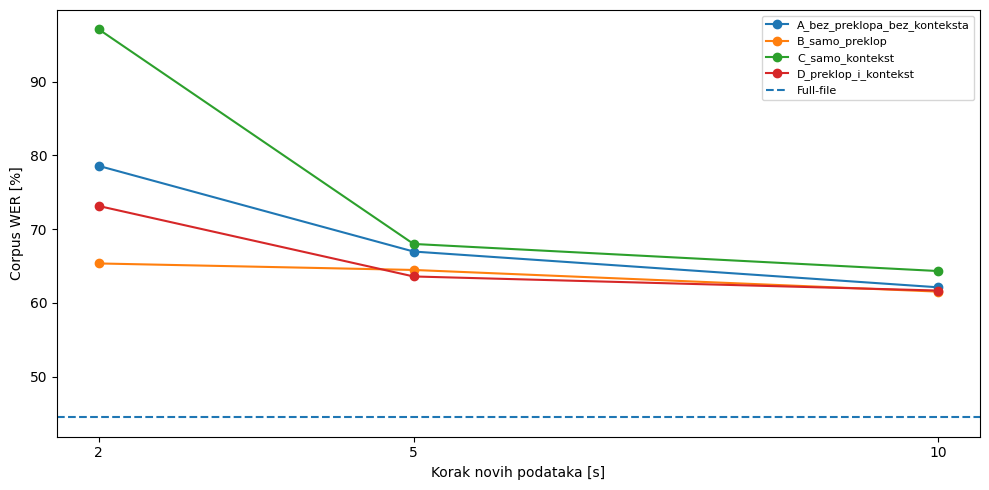

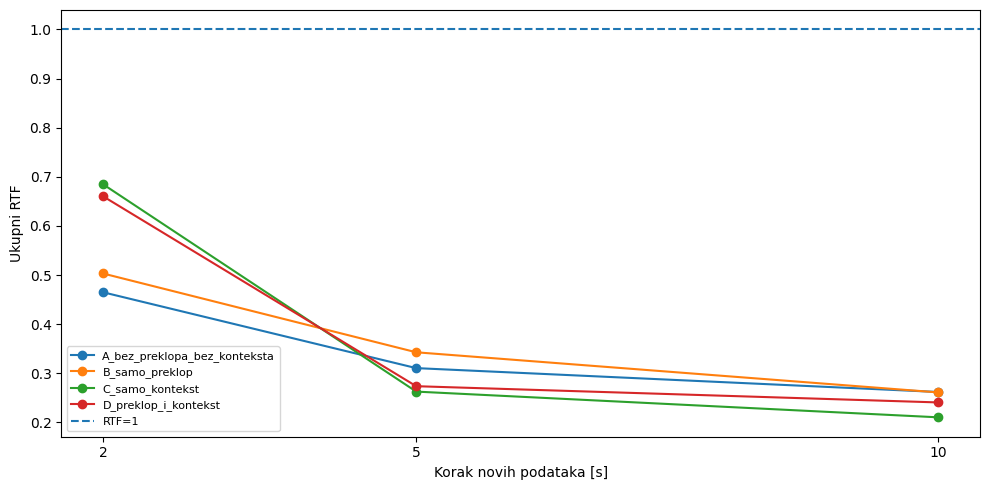

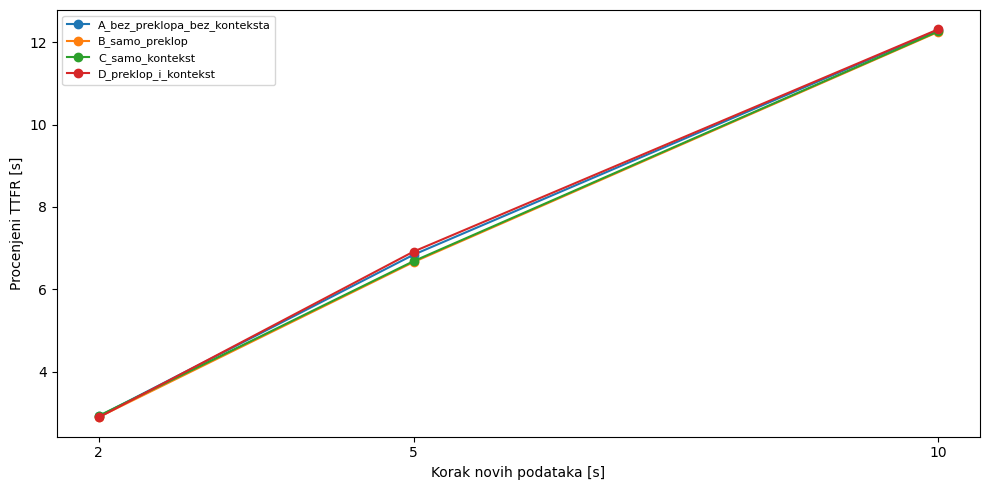

Sačuvano u: D:\0000000000MasterRad\aleksandar_jovanović_Faster-Whisper&CTranslate2_2026\Projekat2ASR\rezultati\07_streaming_chunking_real_time
GLAVNI EKSPERIMENT: proveri transkripte, broj reči i rezultate pre konačnog izbora konfiguracije.


In [12]:
def corpus_wer_odvojeno(df):
    S=D=I=H=0
    for r in df.itertuples():
        p = process_words(normalizuj_tekst(r.Referenca), normalizuj_tekst(r.Transkript))
        S += p.substitutions; D += p.deletions; I += p.insertions; H += p.hits
    n = S+D+H
    return 100*(S+D+I)/n if n else np.nan

rezime=[]
for (rezim, chunk), grupa in df_fajlovi.groupby(['Rezim','Chunk_s'],sort=False):
    rezime.append(dict(Rezim=rezim, Chunk_s=chunk,
        Corpus_WER=corpus_wer_odvojeno(grupa), Makro_WER=grupa.WER.mean(),
        RTF=grupa.Ukupno_inference_s.sum()/grupa.Trajanje_s.sum(),
        Prosecna_TTFR_s=grupa.TTFR_s.mean(),
        Prosecni_max_queue_s=grupa.Max_queue_s.mean(),
        Sumnjivi_WER_preko_100=int((grupa.WER>100).sum()),
        Sumnjivi_odnos_reci=int((grupa.Broj_reci_hyp > 2*grupa.Broj_reci_ref).sum())))
df_rezime=pd.DataFrame(rezime)
display(df_rezime.round(3))

baseline_corpus=corpus_wer_odvojeno(df_baseline)
print(f'Full-file corpus WER: {baseline_corpus:.2f}%')

for metrika, naslov in [('Corpus_WER','Corpus WER [%]'),('RTF','Ukupni RTF'),('Prosecna_TTFR_s','Procenjeni TTFR [s]')]:
    plt.figure(figsize=(10,5))
    for naziv,g in df_rezime.groupby('Rezim'):
        plt.plot(g.Chunk_s,g[metrika],marker='o',label=naziv)
    if metrika=='Corpus_WER': plt.axhline(baseline_corpus,ls='--',label='Full-file')
    if metrika=='RTF': plt.axhline(1,ls='--',label='RTF=1')
    plt.xlabel('Korak novih podataka [s]'); plt.ylabel(naslov)
    plt.xticks(CHUNK_VELICINE); plt.legend(fontsize=8); plt.tight_layout()
    plt.savefig(REZULTATI_DIR / f'07_FINAL_{metrika}.png',dpi=150)
    plt.show()

# Sačuvaj sve transkripte i dijagnostiku, uključujući potencijalno neuspešne režime.
df_baseline.to_csv(REZULTATI_DIR/'07_FINAL_full_file.csv',index=False,encoding='utf-8-sig')
df_fajlovi.to_csv(REZULTATI_DIR/'07_FINAL_fajlovi.csv',index=False,encoding='utf-8-sig')
df_chunkovi.to_csv(REZULTATI_DIR/'07_FINAL_chunkovi.csv',index=False,encoding='utf-8-sig')
df_rezime.to_csv(REZULTATI_DIR/'07_FINAL_rezime.csv',index=False,encoding='utf-8-sig')
print('Sačuvano u:',REZULTATI_DIR)
print('GLAVNI EKSPERIMENT: proveri transkripte, broj reči i rezultate pre konačnog izbora konfiguracije.')

### Zaključak eksperimenta

Najniži korpusni WER u segmentnoj obradi iznosi 61,53%, pri koraku od 10 sekundi i režimu sa akustičkim preklapanjem. Kraći koraci omogućavaju ranije dobijanje rezultata, ali uglavnom povećavaju grešku. Obrada celih snimaka ostvarila je bolju tačnost (WER 44,49%) od svih segmentnih konfiguracija. Rezultati potvrđuju kompromis između tačnosti i vremena do prvog rezultata.